# Task 2 · Exploratory Data Analysis & Data Cleaning
**PowerCo SME churn (BCG X Data Science Job Simulation, Forage)**

Hypothesis from the client: *SME customers are churning because they are price-sensitive.*
Goal of this notebook: understand both datasets, check data quality, and look for early evidence for or against the price-sensitivity hypothesis before building features.

1. Load & check data quality
2. Churn overview
3. Churn by customer segment (channel, campaign, tenure, products)
4. Consumption & margin
5. Price data: did prices actually move?
6. Save a clean dataset for feature engineering

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 40)

## 1. Load & check data quality

In [2]:
client = pd.read_csv("../data/client_data.csv")
price = pd.read_csv("../data/price_data.csv", parse_dates=["price_date"])
print(f"client: {client.shape[0]:,} rows x {client.shape[1]} cols")
print(f"price:  {price.shape[0]:,} rows x {price.shape[1]} cols")

client: 14,606 rows x 26 cols
price:  193,002 rows x 8 cols


In [3]:
quality = pd.DataFrame({
    "dataset": ["client", "price"],
    "missing_values": [client.isna().sum().sum(), price.isna().sum().sum()],
    "duplicate_ids_or_rows": [client["id"].duplicated().sum(), price.duplicated(["id", "price_date"]).sum()],
    "unique_clients": [client["id"].nunique(), price["id"].nunique()],
})
quality

,dataset,missing_values,duplicate_ids_or_rows,unique_clients
0,client,0,0,14606
1,price,0,0,16096


In [4]:
# Categorical fields use the placeholder 'MISSING' rather than NaN
for col in ["channel_sales", "origin_up"]:
    print(col, "-> 'MISSING' share:", round((client[col] == "MISSING").mean(), 3))

channel_sales -> 'MISSING' share: 0.255
origin_up -> 'MISSING' share: 0.004


In [5]:
client.describe().T[['mean', '50%', 'max']].round(2)

,mean,50%,max
cons_12m,159220.29,14115.50,6207104.00
cons_gas_12m,28092.38,0.00,4154590.00
cons_last_month,16090.27,792.50,771203.00
forecast_cons_12m,1868.61,1112.88,82902.83
forecast_cons_year,1399.76,314.00,175375.00
forecast_discount_energy,0.97,0.00,30.00
forecast_meter_rent_12m,63.09,18.80,599.31
forecast_price_energy_off_peak,0.14,0.14,0.27
forecast_price_energy_peak,0.05,0.08,0.20
forecast_price_pow_off_peak,43.13,44.31,59.27


**Data quality notes**
- No NaNs and no duplicate client IDs. Every client in `client_data` has a 2015 monthly price history (the price file also covers ~1,500 IDs not in the client table, which drop out when joining).
- `channel_sales` and `origin_up` encode unknowns as the string `MISSING` — kept as its own category.
- Consumption and margin columns are heavily right-skewed (mean far above median), which will need a log transform before modelling.

## 2. Churn overview

Overall churn rate: 9.7%  (1,419 of 14,606 SME clients)


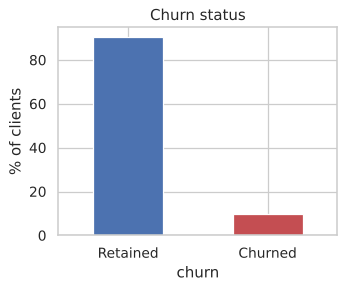

In [6]:
churn_rate = client["churn"].mean()
print(f"Overall churn rate: {churn_rate:.1%}  ({client['churn'].sum():,} of {len(client):,} SME clients)")

fig, ax = plt.subplots(figsize=(4, 3))
client["churn"].map({0: "Retained", 1: "Churned"}).value_counts(normalize=True).mul(100).plot.bar(ax=ax, color=["#4C72B0", "#C44E52"])
ax.set_ylabel("% of clients"); ax.set_title("Churn status"); ax.tick_params(axis="x", rotation=0)

About 1 in 10 SME clients churned — an imbalanced target, so accuracy alone will be misleading in modelling.

## 3. Churn by customer segment

In [7]:
def churn_by(col, min_size=50):
    out = client.groupby(col)["churn"].agg(churn_rate="mean", clients="size")
    return out[out["clients"] >= min_size].sort_values("churn_rate", ascending=False)

# Long hashed category names -> short readable labels
def short(s):
    return s.str[:6]

seg = {}
for col in ["channel_sales", "origin_up", "num_years_antig", "nb_prod_act", "has_gas"]:
    seg[col] = churn_by(col)
seg["channel_sales"].round(3)

,churn_rate,clients
channel_sales,,
foosdfpfkusacimwkcsosbicdxkicaua,0.121,6754
usilxuppasemubllopkaafesmlibmsdf,0.100,1375
ewpakwlliwisiwduibdlfmalxowmwpci,0.084,893
MISSING,0.076,3725
lmkebamcaaclubfxadlmueccxoimlema,0.056,1843


In [8]:
seg['origin_up'].round(3)

,churn_rate,clients
origin_up,,
lxidpiddsbxsbosboudacockeimpuepw,0.126,7097
ldkssxwpmemidmecebumciepifcamkci,0.084,3148
MISSING,0.062,64
kamkkxfxxuwbdslkwifmmcsiusiuosws,0.060,4294


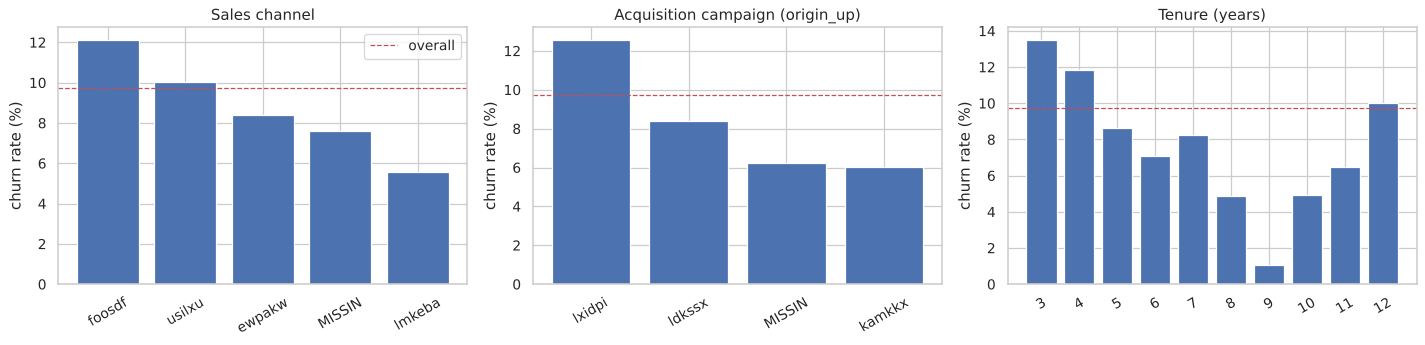

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col, title in zip(axes, ["channel_sales", "origin_up", "num_years_antig"],
                          ["Sales channel", "Acquisition campaign (origin_up)", "Tenure (years)"]):
    d = seg[col].copy()
    if col != "num_years_antig":
        d.index = d.index.str[:6]
    else:
        d = d.sort_index()
    ax.bar(d.index.astype(str), d["churn_rate"] * 100, color="#4C72B0")
    ax.axhline(churn_rate * 100, color="#C44E52", ls="--", lw=1, label="overall")
    ax.set_title(title); ax.set_ylabel("churn rate (%)"); ax.tick_params(axis="x", rotation=30)
axes[0].legend()
plt.tight_layout()

In [10]:
pd.concat({'has_gas': seg['has_gas'], 'nb_prod_act': seg['nb_prod_act']}).round(3)

churn_rate  clients
has_gas     f       0.101    11955
            t       0.082     2651
nb_prod_act 4       0.100      150
            1       0.100    11431
            3       0.099      523
            2       0.085     2445

**Segment findings**
- **Tenure** is the clearest pattern: clients in their 3rd year churn at ~13.5%, vs ~7% at 6 years.
- **Sales channel** and **acquisition campaign** matter: the worst channel/campaign churn at ~12–13%, the best at ~6%.
- Gas customers churn slightly less (8.2% vs 10.1%) — buying more products from PowerCo may raise switching costs.

## 4. Consumption & margin

In [11]:
num_cols = ["cons_12m", "cons_last_month", "forecast_cons_12m", "net_margin", "margin_net_pow_ele", "pow_max"]
client.groupby("churn")[num_cols].median().T.rename(columns={0: "retained (median)", 1: "churned (median)"}).round(2)

churn,retained (median),churned (median)
cons_12m,14075.00,14529.00
cons_last_month,800.00,740.00
forecast_cons_12m,1108.55,1152.35
net_margin,111.86,121.86
margin_net_pow_ele,21.48,26.04
pow_max,13.86,13.86


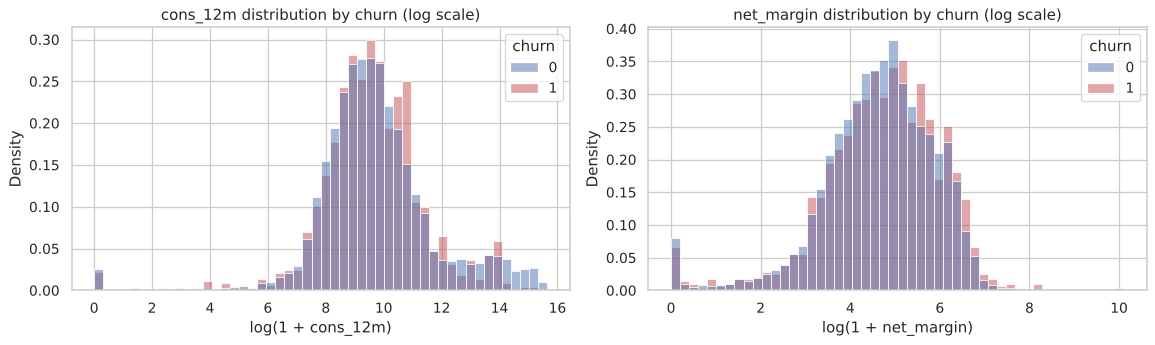

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, col in zip(axes, ["cons_12m", "net_margin"]):
    sns.histplot(data=client, x=np.log1p(client[col].clip(lower=0)), hue="churn", stat="density",
                 common_norm=False, bins=50, ax=ax, palette=["#4C72B0", "#C44E52"])
    ax.set_xlabel(f"log(1 + {col})"); ax.set_title(f"{col} distribution by churn (log scale)")
plt.tight_layout()

Consumption distributions of churned and retained clients overlap almost completely. Churned clients have a slightly **higher** median margin on power — they are not obviously the low-value, price-squeezed customers the hypothesis implies.

## 5. Price data: did prices actually move in 2015?

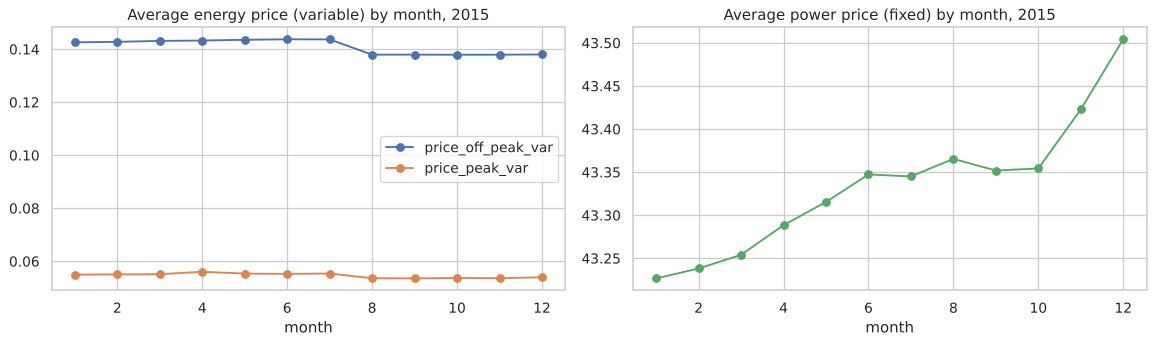

In [13]:
monthly = price.groupby(price["price_date"].dt.month)[["price_off_peak_var", "price_peak_var", "price_off_peak_fix"]].mean()
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
monthly[["price_off_peak_var", "price_peak_var"]].plot(ax=axes[0], marker="o", title="Average energy price (variable) by month, 2015")
monthly["price_off_peak_fix"].plot(ax=axes[1], marker="o", color="#55A868", title="Average power price (fixed) by month, 2015")
for ax in axes: ax.set_xlabel("month")
plt.tight_layout()

In [14]:
p = price.sort_values("price_date")
first, last = p.groupby("id").first(), p.groupby("id").last()
change = (last["price_off_peak_var"] - first["price_off_peak_var"]).rename("offpeak_energy_change")

direction = pd.cut(change, [-np.inf, -1e-4, 1e-4, np.inf], labels=["decreased", "flat", "increased"])
summary = (client.set_index("id").join(direction.rename("price_direction"))
           .groupby("price_direction", observed=True)["churn"].agg(clients="size", churn_rate="mean"))
summary["share_of_clients"] = summary["clients"] / summary["clients"].sum()
summary.round(3)

,clients,churn_rate,share_of_clients
price_direction,,,
decreased,13866,0.097,0.949
flat,119,0.017,0.008
increased,621,0.116,0.043


**Price findings**
- Off-peak energy prices **fell for ~95% of clients** during 2015; only ~4% saw an increase.
- Clients whose price went up churn somewhat more (11.6% vs 9.7%), but they are a tiny group, so price changes can explain very little of total churn.
- Early read: the data do not support price as the main driver. Tenure, channel and campaign look more important — to be tested properly with engineered features and a model.

## 6. Save a clean dataset

In [15]:
clean = client.copy()
for col in ["date_activ", "date_end", "date_modif_prod", "date_renewal"]:
    clean[col] = pd.to_datetime(clean[col], format="%Y-%m-%d")
clean["has_gas"] = clean["has_gas"].map({"t": 1, "f": 0})
clean.to_csv("../data/clean_data_after_eda.csv", index=False)
print("saved clean_data_after_eda.csv", clean.shape)

saved clean_data_after_eda.csv (14606, 26)
